In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
from crafts_stack.utils import read_h5_data_with_mask
from mytools.data import vitems, h5, save_h5, read_h5, save_attrs
from mytools.estimate_fixwidth import get_signal_level_fixwidth, get_null_test_results

from mytools.plot import (
make_figure, 
plot_heatmap, 
set_ticks, 
plot_axlines, 
save_plot, 
plt, 
plot_heatmaps, 
plot_sector,
plot_line
)
from mytools.plot_custom import (
plot_profile_fixwidth_2c, plot_profile_fixwidth_2c, plot_profile_2r, plot_stack_fit_res, compare_profiles
)

# CRAFTS arPLS - analytical

In [3]:
path_analytical = "../../data/crafts_df122k_xsize3000_nfs10_mean_analytical_result.h5"
vitems(path_analytical)

Item: crafts_df122k_arpls_rmfg_xsize3000_nfs10
Type: Group
Attributes (0):
 None
Item: crafts_df122k_arpls_rmfg_xsize3000_nfs10/fit_mask
Type: Dataset
Shape: (120, 120)
Dtype: bool
Attributes (0):
 None
Item: crafts_df122k_arpls_rmfg_xsize3000_nfs10/fitted
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: crafts_df122k_arpls_rmfg_xsize3000_nfs10/jk_mean_residual
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: crafts_df122k_arpls_rmfg_xsize3000_nfs10/jk_std
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: crafts_df122k_arpls_rmfg_xsize3000_nfs10/param_cov
Type: Dataset
Shape: (7, 7)
Dtype: float64
Attributes (0):
 None
Item: crafts_df122k_arpls_rmfg_xsize3000_nfs10/peak_mask
Type: Dataset
Shape: (120, 120)
Dtype: bool
Attributes (0):
 None
Item: crafts_df122k_arpls_rmfg_xsize3000_nfs10/residual
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: crafts_df122k_arpls_rmfg_xsize3000_nfs10/s

In [4]:
arpls_key = 'crafts_df122k_arpls_rmfg_xsize3000_nfs10'
arpls_result_analytical = read_h5_data_with_mask(path_analytical, [arpls_key])

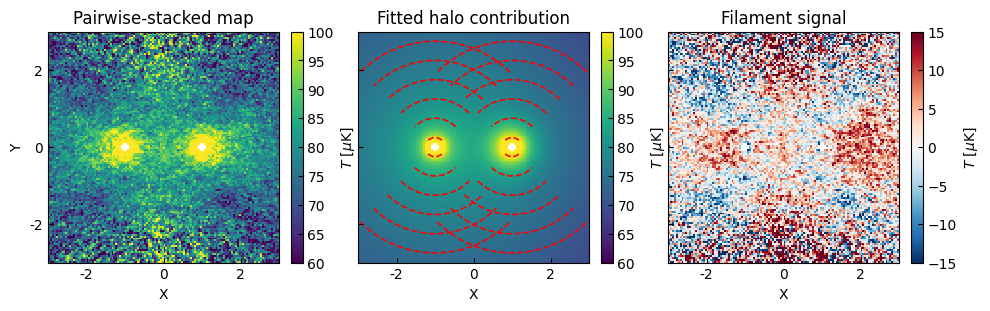

In [6]:
axes = plot_stack_fit_res(
    [arpls_result_analytical[arpls_key]['stack'], arpls_result_analytical[arpls_key]['fitted'], arpls_result_analytical[arpls_key]['residual']], 
    norm='linear', 
    cmap=['viridis','viridis','RdBu_r'],
    vmax=[100, 100, 15],
    vmin=[60, 60, -15]
)
plot_sector(axes[1], ec='r')

fname = 'img_crafts_df122k_arpls_rmfg_xsize3000_nfs10_mean_halofitting_analytical_stack_fit_res.png'
# save_plot(axes, fname)

In [7]:
fix_width = 0.3
d = arpls_result_analytical[arpls_key]['residual']
d_err = arpls_result_analytical[arpls_key]['jk_std']

line_x_analytical, line_y_analytical, line_yerr_analytical, _, _ = get_signal_level_fixwidth(d, fix_width, d_err);

# CRAFTS arPLS - numerical

In [8]:
path_numerical = "../../data/crafts_df122k_xsize3000_nfs10_mean_numerical_result.h5"
vitems(path_numerical)

Item: crafts_df122k_arpls_rmfg_xsize3000_nfs10
Type: Group
Attributes (0):
 None
Item: crafts_df122k_arpls_rmfg_xsize3000_nfs10/fit_mask
Type: Dataset
Shape: (120, 120)
Dtype: bool
Attributes (0):
 None
Item: crafts_df122k_arpls_rmfg_xsize3000_nfs10/fitted
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: crafts_df122k_arpls_rmfg_xsize3000_nfs10/jk_mean_residual
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: crafts_df122k_arpls_rmfg_xsize3000_nfs10/jk_std
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: crafts_df122k_arpls_rmfg_xsize3000_nfs10/peak_mask
Type: Dataset
Shape: (120, 120)
Dtype: bool
Attributes (0):
 None
Item: crafts_df122k_arpls_rmfg_xsize3000_nfs10/residual
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: crafts_df122k_arpls_rmfg_xsize3000_nfs10/stack
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: crafts_df122k_rmfg10_xsize3000_nfs10
Type:

In [9]:
arpls_result_numerical = read_h5_data_with_mask(path_numerical, [arpls_key])

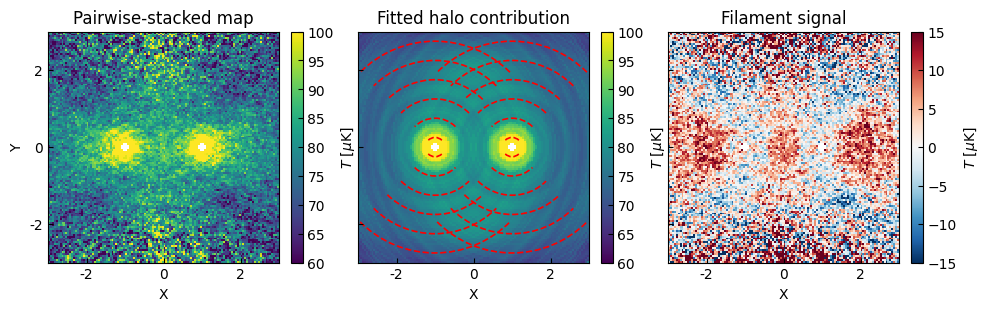

In [11]:
axes = plot_stack_fit_res(
    [arpls_result_numerical[arpls_key]['stack'], arpls_result_numerical[arpls_key]['fitted'], arpls_result_numerical[arpls_key]['residual']], 
    norm='linear', 
    cmap=['viridis','viridis','RdBu_r'],
    vmax=[100, 100, 15],
    vmin=[60, 60, -15]
)
plot_sector(axes[1], ec='r')

fname = 'img_crafts_df122k_arpls_rmfg_xsize3000_nfs10_mean_halofitting_numerical_stack_fit_res.png'
# save_plot(axes, fname)

In [12]:
d = arpls_result_numerical[arpls_key]['residual']
d_err = arpls_result_numerical[arpls_key]['jk_std']

line_x_numerical, line_y_numerical, line_yerr_numerical, _, _ = get_signal_level_fixwidth(d, fix_width, d_err);

# overall plot

In [13]:
lx_list = [line_x_analytical, line_x_numerical]
ly_list = [line_y_analytical, line_y_numerical]
lyerr_list = [line_yerr_analytical, line_yerr_numerical]
dict_list = [arpls_result_analytical, arpls_result_numerical]

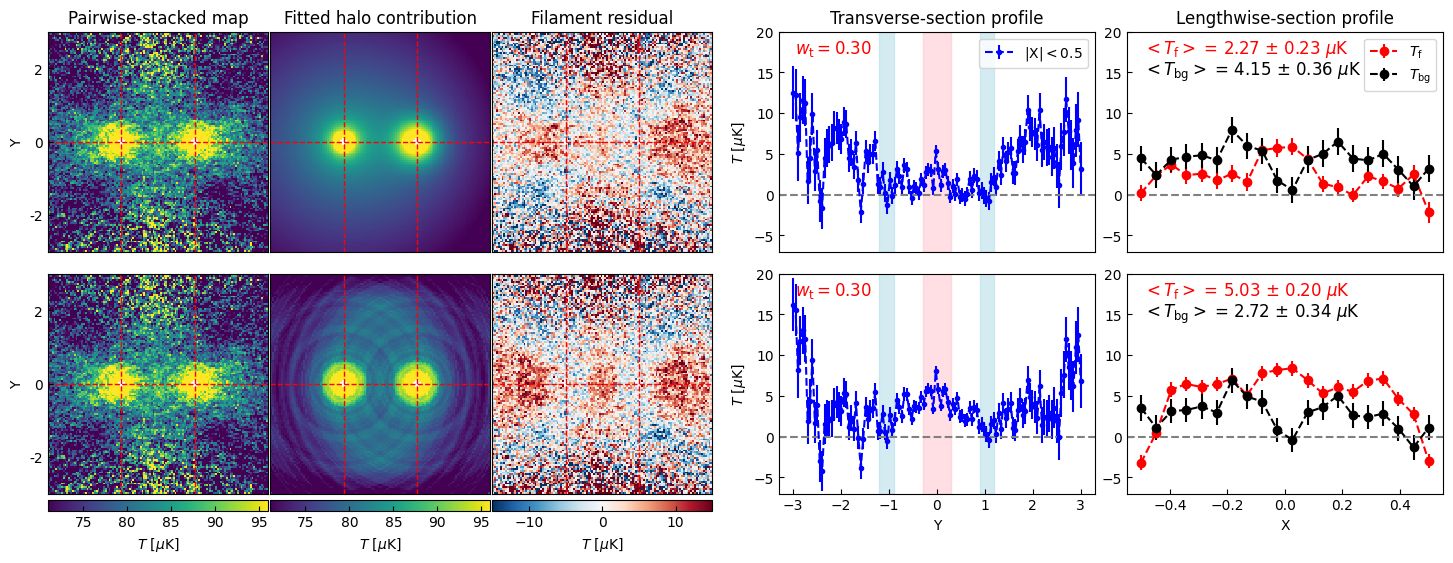

In [15]:
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec

nrows, ncols = 2, 5

fig = plt.figure(figsize=(18,6))

gs_main = GridSpec(1, 2, figure=fig, width_ratios=[10, 10], wspace=0.1)

gs_left = GridSpecFromSubplotSpec(nrows, 3, subplot_spec=gs_main[0],
                                  wspace=0.01, hspace=0.1)

gs_right = GridSpecFromSubplotSpec(nrows, 2, subplot_spec=gs_main[1],
                                   wspace=0.1, 
                                   hspace=0.1)

axes = np.empty((nrows, ncols), dtype=object)

for i in range(nrows):
    for j in range(3):
        axes[i, j] = fig.add_subplot(gs_left[i, j])
        axes[i, j].set_aspect('equal')

for i in range(nrows):
    for j in range(2):
        axes[i, j+3] = fig.add_subplot(gs_right[i, j])
        axes[i, j+3].set_aspect('auto')
            

# fig, axes = make_figure(2,5,figsize=(18,6), wspace=0.5, hspace=0.01)
for i, _dict, _lx, _ly, _lyerr in zip(range(2), dict_list, lx_list, ly_list, lyerr_list):
    _ax = axes[i]
    plot_heatmap(_dict[arpls_key]['stack'], 
                 ax=_ax[0], cbar_label=r'$T\ [\mu$K]',
                 title='Pairwise-stacked map' if i==0 else '',
                 vmax=96, vmin=71, show_cbar=True if i==1 else False, cbar_loc='bottom', 
                )
    plot_heatmap(_dict[arpls_key]['fitted'],
                 ax=_ax[1], cbar_label=r'$T\ [\mu$K]',
                 title='Fitted halo contribution' if i==0 else '',
                 vmax=96, vmin=71, show_cbar=True if i==1 else False, cbar_loc='bottom', 
                )
    plot_heatmap(_dict[arpls_key]['residual'], 
                 ax=_ax[2], cbar_label=r'$T\ [\mu$K]',
                 title='Filament residual' if i==0 else '', 
                 vmax=15, vmin=-15, show_cbar=True if i==1 else False, cbar_loc='bottom',
                 cmap='RdBu_r'
                )
    # plot_line([_lx[0]], [_ly[0]], y_err=[_lyerr[0]],
    #           ax=_ax[3], marker='o', linestyle='', 
    #           title="Transverse-section profile" if i==0 else '',
    #           ylabel=r'$T\ [\mu$K]', xlabel='Y'if i==1 else '',
    #           # color='b',
    #          )
    # plot_line(_lx[1:], _ly[1:], y_err=_lyerr[1:],
    #           ax=_ax[4], marker='s', linestyle='-', 
    #           title="Lengthwise-section profile" if i==0 else '',
    #           ylabel='', xlabel='X'if i==1 else '', 
    #           color=['r', 'k'],
    #          )
    if i==0:
        plot_profile_fixwidth_2c(_lx, _ly, y_err=_lyerr, axes=_ax[3:], width=fix_width)
    else:
        plot_profile_fixwidth_2c(_lx, _ly, y_err=_lyerr, axes=_ax[3:], width=fix_width, label=None, title=None)

    _ax[0].xaxis.set_visible(False)
    _ax[1].xaxis.set_visible(False)
    _ax[2].xaxis.set_visible(False)
    # _ax[0].yaxis.set_visible(False)
    _ax[1].yaxis.set_visible(False)
    _ax[2].yaxis.set_visible(False)
    
axes[0,3].xaxis.set_visible(False)
axes[0,4].xaxis.set_visible(False)

axes[0,3].set_ylim(-7, 20)
axes[0,4].set_ylim(-7, 20)
axes[1,3].set_ylim(-7, 20)
axes[1,4].set_ylim(-7, 20)


plot_axlines(axes[:,:3], vl=[40,80], hl=[60])
# plot_axlines(axes[:,3:], hl=[0], color='k', alpha=0.5, linewidth=2)

In [16]:
fname = 'img_crafts_df122k_arpls_rmfg_xsize3000_nfs10_mean_halofitting_analytical_numerical_stack_fit_res_profiles.png'
save_plot(fig, fname, dpi=300)

Plot saved to img_crafts_df122k_arpls_rmfg_xsize3000_nfs10_mean_halofitting_analytical_numerical_stack_fit_res_profiles.png
